In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
DATA_DIR = Path("/kaggle/input/indo-fashion-dataset")   # input datasets are read-only
OUT_DIR  = Path("/kaggle/working/data/processed"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = Path("/kaggle/working/images");         FIG_DIR.mkdir(exist_ok=True)

In [ ]:
# LOADING THE DATASET 

In [5]:
import json, re, html
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_DIR = Path("/kaggle/input/datasets/validmodel/indo-fashion-dataset")
OUT_DIR  = Path("/kaggle/working/data/processed"); OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = Path("/kaggle/working/images");         FIG_DIR.mkdir(exist_ok=True)

FILES = {"train": "train_data.json", "val": "val_data.json", "test": "test_data.json"}
CHECK_IMAGES = False   # set True only if you downloaded the images

In [ ]:
# SPLIT DATA AND LOOK AT THE SHAPE

In [6]:
frames = []
for split, fname in FILES.items():
    part = pd.read_json(DATA_DIR / fname, lines=True)
    part["split"] = split
    frames.append(part)

df = pd.concat(frames, ignore_index=True)
rows_raw = len(df)
print("Shape:", df.shape)
df.head()

Shape: (106166, 7)


,image_url,image_path,brand,product_title,class_label,color,split
0,https://m.media-amazon.com/images/I/81XKaSKvly...,images/train/0.jpeg,Womanista,Women's Georgette Saree with Blouse Piece (TKI...,saree,NaN,train
1,https://m.media-amazon.com/images/I/91dDMDg+QT...,images/train/1.jpeg,Yashika,Women Linen Printed Sarees Free Size (BEE),saree,NaN,train
2,https://m.media-amazon.com/images/I/71TJ9p46PV...,images/train/2.jpeg,Womanista,Organza Floral Print Saree with Blouse Piece(W...,saree,NaN,train
3,https://m.media-amazon.com/images/I/81Y+je7CEg...,images/train/3.jpeg,PERFECTBLUE,Women's Digital Cotton Linen Blend Saree with ...,saree,NaN,train
4,https://m.media-amazon.com/images/I/61B8o9Ulqp...,images/train/4.jpeg,VAIVIDHYAM,Designer Sarees Women's Banarasi Cotton Silk S...,saree,NaN,train


In [7]:
df.info()
print()
print(df["split"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106166 entries, 0 to 106165
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   image_url      106166 non-null  object
 1   image_path     106166 non-null  object
 2   brand          106166 non-null  object
 3   product_title  106166 non-null  object
 4   class_label    106166 non-null  object
 5   color          11854 non-null   object
 6   split          106166 non-null  object
dtypes: object(7)
memory usage: 5.7+ MB

split
train    91166
val       7500
test      7500
Name: count, dtype: int64


*****Adding missing value placeholder**

In [ ]:
text_cols = df.select_dtypes(include="object").columns
for c in text_cols:
    df[c] = df[c].astype("string").str.strip()

PLACEHOLDERS = ["NA", "N/A", "na", "n/a", "NaN", "nan", "None", "null", "-", ""]
df = df.replace(PLACEHOLDERS, np.nan)
df = df.replace({pd.NA: np.nan})

In [17]:
MISSING VALUES

SyntaxError: invalid syntax (1843082877.py, line 1)

,missing,percent
color,91963,94.98
image_url,0,0.00
image_path,0,0.00
brand,0,0.00
product_title,0,0.00
class_label,0,0.00
split,0,0.00
product_title_raw,0,0.00
title_words,0,0.00
title_chars,0,0.00


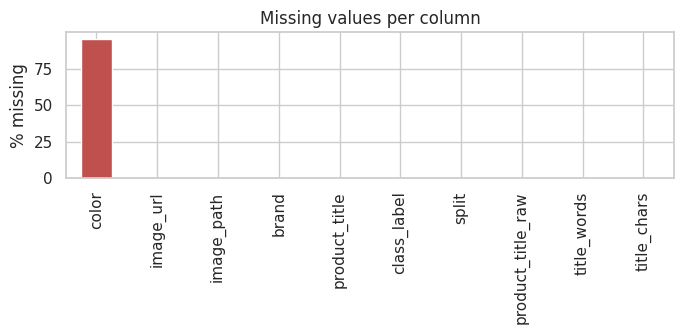

In [18]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing", ascending=False)
display(missing)

ax = missing["percent"].plot(kind="bar", figsize=(7, 3.5), color="#c0504d")
ax.set_ylabel("% missing"); ax.set_title("Missing values per column")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_missing_values.png", dpi=150); plt.show()

In [12]:
before = len(df)
df = df.dropna(subset=["class_label", "product_title"])
print(f"Dropped {before - len(df)} rows missing class_label or product_title")

df["brand"] = df["brand"].fillna("unknown")
print("Remaining missing values:\n", df.isna().sum())

Dropped 6445 rows missing class_label or product_title
Remaining missing values:
 image_url            0
image_path           0
brand                0
product_title        0
class_label          0
color            94848
split                0
dtype: int64


In [ ]:
# INCONSISTENT FORMATS


In [13]:
# keep the original title so we can compare before/after
df["product_title_raw"] = df["product_title"]

# 1. make everything lowercase and remove extra spaces
df["class_label"] = df["class_label"].str.lower().str.strip()
df["product_title"] = df["product_title"].str.lower().str.strip()
df["brand"] = df["brand"].str.lower().str.strip()

# 2. remove special characters from titles (keep letters and numbers)
df["product_title"] = df["product_title"].str.replace(r"[^a-z0-9 ]", " ", regex=True)

# 3. turn multiple spaces into one space
df["product_title"] = df["product_title"].str.replace(r"\s+", " ", regex=True).str.strip()

# check the result
print("Number of classes:", df["class_label"].nunique(), "(expected 15)")
print(sorted(df["class_label"].unique()))
df[["product_title_raw", "product_title"]].sample(5, random_state=1)

Number of classes: 15 (expected 15)
['blouse', 'dhoti_pants', 'dupattas', 'gowns', 'kurta_men', 'leggings_and_salwars', 'lehenga', 'mojaris_men', 'mojaris_women', 'nehru_jackets', 'palazzos', 'petticoats', 'saree', 'sherwanis', 'women_kurta']


,product_title_raw,product_title
50803,Women's Satin Semi-stitched Lehenga Choli,women s satin semi stitched lehenga choli
82097,Bottoms Womens Kurta and Palazzo Set (White) F...,bottoms womens kurta and palazzo set white fre...
62934,Men's Red Cotton Nehru Jacket,men s red cotton nehru jacket
93933,Premium Cotton Men's Ethnic and Stylish Kurta ...,premium cotton men s ethnic and stylish kurta ...
10770,Rust Red Silk Blend Embroidered Saree with Uns...,rust red silk blend embroidered saree with uns...


In [ ]:
DUPLICATEE

In [14]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate image_url :", df.duplicated(subset=["image_url"]).sum())
print("Duplicate titles    :", df.duplicated(subset=["product_title"]).sum(), "(informational only)")

urls = df.dropna(subset=["image_url"]).groupby("image_url")["split"].nunique()
leak = urls[urls > 1]
print("Image URLs shared across splits (leakage):", len(leak))

Exact duplicate rows: 0
Duplicate image_url : 2894
Duplicate titles    : 35136 (informational only)
Image URLs shared across splits (leakage): 723


In [15]:
before = len(df)

# 1. remove rows that are exactly the same
df = df.drop_duplicates()

# 2. put test first, then val, then train
order = {"test": 0, "val": 1, "train": 2}
df = df.sort_values("split", key=lambda x: x.map(order))

# 3. if the same image appears twice, keep the first one (test/val win over train)
same_image = df["image_url"].duplicated() & df["image_url"].notna()
df = df[~same_image]

# 4. put the rows back in original order
df = df.sort_index()

print(f"Removed {before - len(df)} duplicate rows")
print(df["split"].value_counts())

Removed 2894 duplicate rows
split
train    83131
test      6879
val       6817
Name: count, dtype: Int64


In [ ]:
#OUTLIERS

Normal range (words): 0 to 21.0


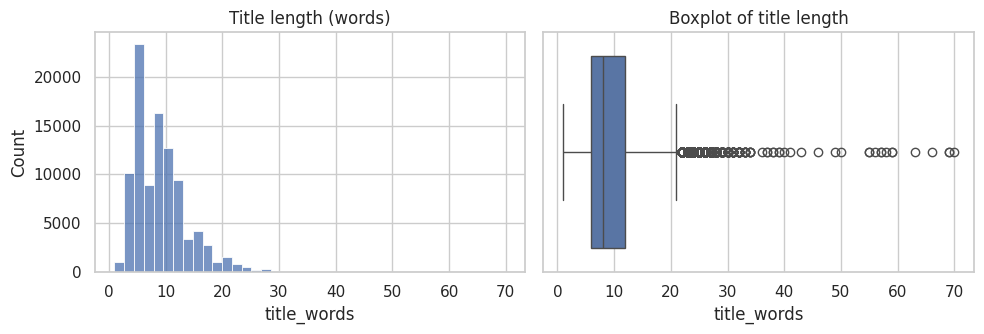

Too short (less than 2 words): 123
Too long (above upper limit): 1991


In [16]:
# 1. count words and characters in each title
df["title_words"] = df["product_title"].str.split().str.len()
df["title_chars"] = df["product_title"].str.len()


# 2. find the "normal" range using IQR
q1 = df["title_words"].quantile(0.25)
q3 = df["title_words"].quantile(0.75)
iqr = q3 - q1
low = max(q1 - 1.5 * iqr, 0)
high = q3 + 1.5 * iqr
print("Normal range (words):", low, "to", high)




# 3. plot title length
plt.figure(figsize=(10, 3.5))

plt.subplot(1, 2, 1)
sns.histplot(df["title_words"], bins=40)
plt.title("Title length (words)")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["title_words"])
plt.title("Boxplot of title length")

plt.tight_layout()
plt.savefig(FIG_DIR / "02_title_length_outliers.png", dpi=150)
plt.show()

# 4. count the outliers
print("Too short (less than 2 words):", (df["title_words"] < 2).sum())
print("Too long (above upper limit):", (df["title_words"] > high).sum())

In [ ]:
before = len(df)
df["long_title_flag"] = df["title_words"] > high
df = df[df["title_words"] >= 2].copy()
print(f"Removed {before - len(df)} very short titles; flagged long titles kept: {df['long_title_flag'].sum()}")

In [ ]:
# FINAL CHECK

Classes: 15
Rows: 106166 raw -> 96827 clean (9339 removed)



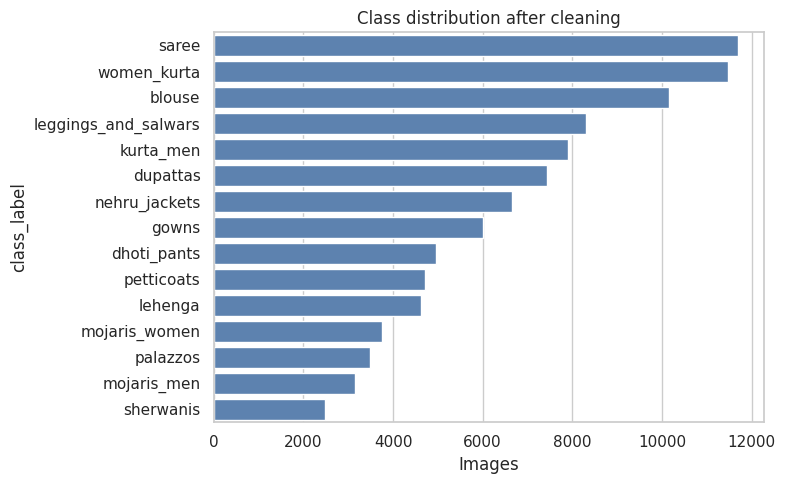

In [19]:
assert df[["class_label", "product_title"]].isna().sum().sum() == 0
assert df.duplicated(subset=["image_url"]).sum() == 0 or df["image_url"].isna().any()
print("Classes:", df["class_label"].nunique())
print(f"Rows: {rows_raw} raw -> {len(df)} clean ({rows_raw - len(df)} removed)\n")


counts = df["class_label"].value_counts()
plt.figure(figsize=(8, 5))
sns.barplot(x=counts.values, y=counts.index, color="#4f81bd")
plt.title("Class distribution after cleaning"); plt.xlabel("Images")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_class_distribution.png", dpi=150); plt.show()

In [ ]:
#eda


In [ ]:
# CLASS DISTRIBUTION

class_label
saree                   11699
women_kurta             11475
blouse                  10168
leggings_and_salwars     8302
kurta_men                7900
dupattas                 7442
nehru_jackets            6653
gowns                    6002
dhoti_pants              4957
petticoats               4723
lehenga                  4618
mojaris_women            3765
palazzos                 3497
mojaris_men              3150
sherwanis                2476
Name: count, dtype: Int64
Biggest / smallest class ratio: 4.72


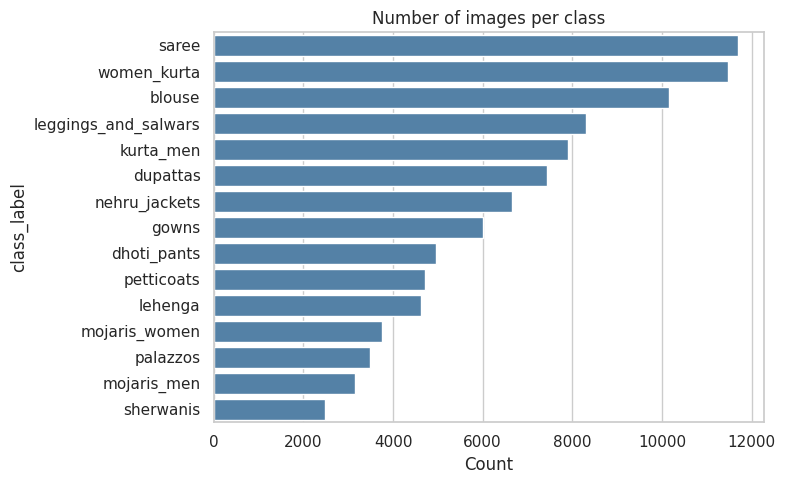

In [20]:
counts = df["class_label"].value_counts()
print(counts)
print("Biggest / smallest class ratio:", round(counts.max() / counts.min(), 2))

plt.figure(figsize=(8, 5))
sns.barplot(x=counts.values, y=counts.index, color="steelblue")
plt.title("Number of images per class")
plt.xlabel("Count")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_class_distribution.png", dpi=150)
plt.show()

In [ ]:
Class balance in each split

split                 test  train  val
class_label                           
blouse                 500   9168  500
dhoti_pants            496   3971  490
dupattas               499   6449  494
gowns                  499   5008  495
kurta_men              500   6900  500
leggings_and_salwars   500   7310  492
lehenga                349   3929  340
mojaris_men            448   2254  448
mojaris_women          467   2831  467
nehru_jackets          438   5776  439
palazzos               420   2667  410
petticoats             441   3843  439
saree                  499  10700  500
sherwanis              324   1848  304
women_kurta            499  10477  499


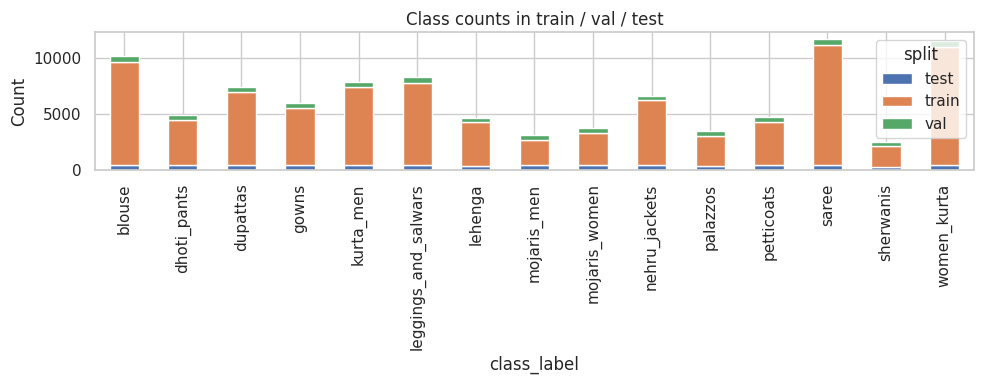

In [21]:
split_counts = pd.crosstab(df["class_label"], df["split"])
print(split_counts)

split_counts.plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Class counts in train / val / test")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_split_distribution.png", dpi=150)
plt.show()

In [ ]:
# heatmap

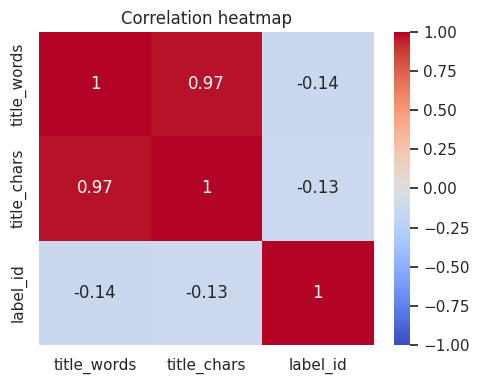

In [22]:
df["label_id"] = df["class_label"].astype("category").cat.codes

plt.figure(figsize=(5, 4))
sns.heatmap(df[["title_words", "title_chars", "label_id"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_correlation.png", dpi=150)
plt.show()

In [ ]:
Title length per class

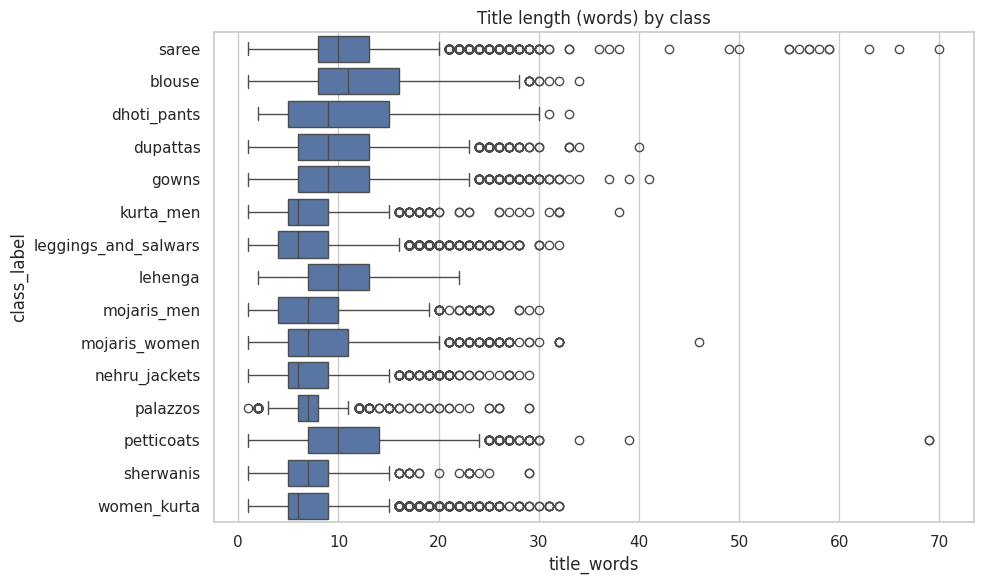

class_label
palazzos                 6.8
sherwanis                7.0
kurta_men                7.1
leggings_and_salwars     7.3
nehru_jackets            7.4
women_kurta              7.6
mojaris_men              7.8
mojaris_women            8.5
lehenga                  9.7
dupattas                10.0
gowns                   10.3
saree                   10.5
dhoti_pants             10.6
petticoats              10.9
blouse                  11.7
Name: title_words, dtype: float64


In [23]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="title_words", y="class_label")
plt.title("Title length (words) by class")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_title_length_by_class.png", dpi=150)
plt.show()

print(df.groupby("class_label")["title_words"].mean().round(1).sort_values())

In [ ]:
Most common words

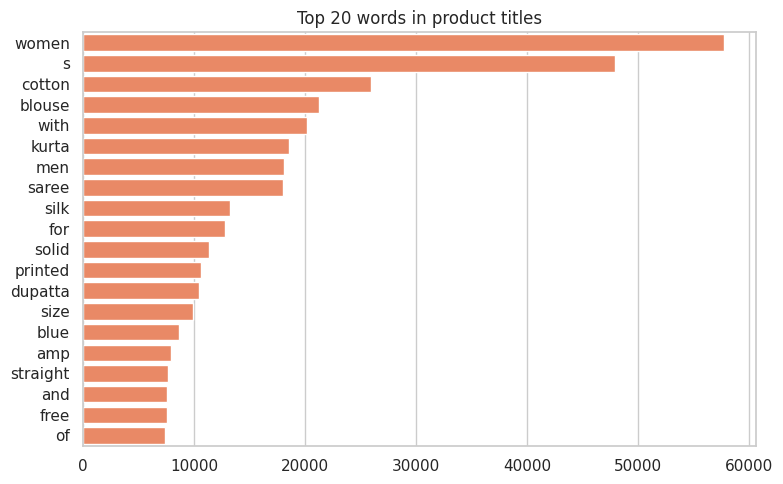

In [24]:
from collections import Counter

all_words = " ".join(df["product_title"]).split()
common = Counter(all_words).most_common(20)
words, freq = zip(*common)

plt.figure(figsize=(8, 5))
sns.barplot(x=list(freq), y=list(words), color="coral")
plt.title("Top 20 words in product titles")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_top_words.png", dpi=150)
plt.show()

In [25]:
Most common words per class

SyntaxError: invalid syntax (672897547.py, line 1)

In [26]:
for label in df["class_label"].unique():
    text = " ".join(df[df["class_label"] == label]["product_title"]).split()
    top = [w for w, c in Counter(text).most_common(5)]
    print(f"{label:25s} -> {top}")

saree                     -> ['saree', 'women', 'with', 'blouse', 's']
blouse                    -> ['blouse', 'women', 's', 'saree', 'readymade']
dhoti_pants               -> ['dhoti', 'women', 's', 'cotton', 'solid']
dupattas                  -> ['dupatta', 'women', 's', 'cotton', 'with']
gowns                     -> ['women', 's', 'gown', 'stitched', 'anarkali']
kurta_men                 -> ['kurta', 'men', 's', 'cotton', 'solid']
leggings_and_salwars      -> ['women', 'solid', 's', 'leggings', 'cotton']
lehenga                   -> ['amp', 'lehenga', 'with', 'semi', 'stitched']
mojaris_men               -> ['men', 's', 'for', 'jutti', 'mojaris']
mojaris_women             -> ['women', 'jutti', 'for', 's', 'mojaris']
nehru_jackets             -> ['jacket', 'men', 'nehru', 's', 'solid']
palazzos                  -> ['women', 'palazzos', 'flared', 'solid', 'trousers']
petticoats                -> ['women', 'petticoat', 'cotton', 's', 'saree']
sherwanis                 -> ['sherwani', '

brand
generic              5955
unknown              3093
aurelia              1193
mirraw               1042
ethnix by raymond     859
w for woman           857
cotton colors         688
biba                  684
deyann                647
hangup                626
Name: count, dtype: Int64
Rows with unknown brand (%): 3.2
Number of unique brands: 8035


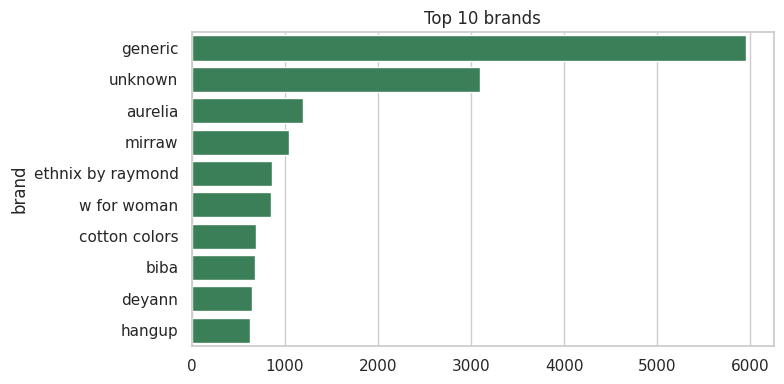

In [27]:
brand_counts = df["brand"].value_counts().head(10)
print(brand_counts)
print("Rows with unknown brand (%):", round((df["brand"] == "unknown").mean() * 100, 1))
print("Number of unique brands:", df["brand"].nunique())

plt.figure(figsize=(8, 4))
sns.barplot(x=brand_counts.values, y=brand_counts.index, color="seagreen")
plt.title("Top 10 brands")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_top_brands.png", dpi=150)
plt.show()

In [ ]:
Scaling usign scaler

In [28]:
from sklearn.preprocessing import StandardScaler

# 1. numeric target for the model
df["label_id"] = df["class_label"].astype("category").cat.codes

# 2. learn the scaling from TRAIN only
cols = ["title_words", "title_chars"]
scaler = StandardScaler()
scaler.fit(df[df["split"] == "train"][cols])

# 3. apply it to everything
df[["title_words_scaled", "title_chars_scaled"]] = scaler.transform(df[cols])

df[["product_title", "class_label", "label_id", "title_words_scaled"]].head()

,product_title,class_label,label_id,title_words_scaled
0,women s georgette saree with blouse piece tkim...,saree,12,0.405939
1,women linen printed sarees free size bee,saree,12,-0.445489
2,organza floral print saree with blouse piece w...,saree,12,0.618796
3,women s digital cotton linen blend saree with ...,saree,12,0.618796
4,designer sarees women s banarasi cotton silk s...,saree,12,0.405939
